In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Dense, Input, GlobalMaxPooling1D
from tensorflow.keras.layers import LSTM, GRU, SimpleRNN, Embedding
from tensorflow.keras.models import Model
from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [3]:
df = pd.read_csv('bbc_text_cls.csv')

In [4]:
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [5]:
df['targets'] = df['labels'].astype("category").cat.codes

In [6]:
# number of classes
K = df['targets'].max() + 1
K

np.int8(5)

In [7]:
df_train, df_test = train_test_split(df, test_size=0.3)

In [8]:
# Convert sentences to sequences
MAX_VOCAB_SIZE = 2000

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
tokenizer.fit_on_texts(df_train['text'])

sequences_train = tokenizer.texts_to_sequences(df_train['text'])
sequences_test = tokenizer.texts_to_sequences(df_test['text'])

In [9]:
# get word -> integer mapping
word2idx = tokenizer.word_index
V = len(word2idx)

print('Found %s unique tokens.' % V)

Found 27773 unique tokens.


In [10]:
# pad sequences so that we get a N x T matrix
data_train = pad_sequences(sequences_train)
print('Shape of data train tensor:', data_train.shape)

Shape of data train tensor: (1557, 2821)


In [11]:
# get sequence length
T = data_train.shape[1]

data_test = pad_sequences(sequences_test, maxlen=T)
print('Shape of data test tensor:', data_test.shape)

Shape of data test tensor: (668, 2821)


In [13]:
# Create the model

# We get to choose embedding dimensionality
D = 20

# Note: we actually want the size of the embedding to be (V + 1) x D,
# because the first index starts from 1 and not 0.
# Thus, if the final index of the embedding matrix is V,
# then it actually must have size V + 1.

i = Input(shape=(T,))
x = Embedding(V + 1, D)(i)
x = LSTM(32, return_sequences=True)(x)
x = GlobalMaxPooling1D()(x)
x = Dense(int(K))(x)

model = Model(i, x)

In [ ]:
# Exercise: try other models
# 1) multiple LSTM layers
# 2) GRU instead of LSTM
# 3) SimpleRNN instead of LSTM
# 4) return_sequences=False, and no maxpool
# 5) For 1-4, try different values of number of hidden units
# 6) Combinations of the above

# Common beginner question:
# "how can I choose the best combination of hyperparameters?"
# This is how! There is no shortcut!

In [14]:
# Compile and fit
model.compile(
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy']
)

print('Training model...')
r = model.fit(
    data_train,
    df_train['targets'],
    epochs=50,
    validation_data=(data_test, df_test['targets'])
)

Training model...
Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 48s 926ms/step - accuracy: 0.2473 - loss: 1.5971 - val_accuracy: 0.3234 - val_loss: 1.5734
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 45s 922ms/step - accuracy: 0.4181 - loss: 1.5630 - val_accuracy: 0.5225 - val_loss: 1.4516
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 45s 917ms/step - accuracy: 0.6037 - loss: 1.2314 - val_accuracy: 0.6497 - val_loss: 0.9381
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 45s 929ms/step - accuracy: 0.7868 - loss: 0.7059 - val_accuracy: 0.7665 - val_loss: 0.7153
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 45s 925ms/step - accuracy: 0.8709 - loss: 0.5940 - val_accuracy: 0.5210 - val_loss: 1.4299
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 944ms/step - accuracy: 0.7945 - loss: 0.6952 - val_accuracy: 0.8922 - val_loss: 0.5252
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 942ms/step - accuracy: 0.9512 - loss: 0.3885 - val_accuracy: 0.9311 - val_loss: 0.4069
Epoch 8/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 936ms/step - accuracy: 0.9730 - loss:

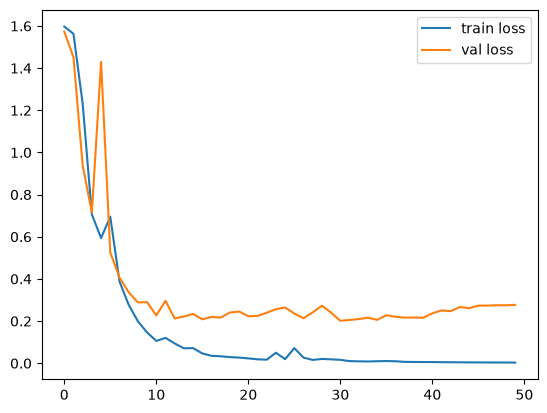

In [15]:
# plot loss per iteration
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend();

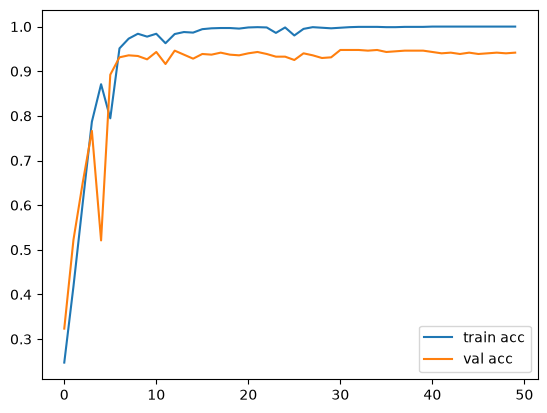

In [16]:
# Plot accuracy per iteration
plt.plot(r.history['accuracy'], label='train acc')
plt.plot(r.history['val_accuracy'], label='val acc')
plt.legend();